# Ideal circuit predictions and paper figures

This notebook checks schedule visibility and system survival, then draws the two main paper panels. It runs the two schedule branches separately and combines their amplitudes for the final plus/minus readout.

The system and memories start in zero. The drive is $H_S=(\Omega/2)\sigma_x$, with $\hbar=1$, and recording gates are ideal CNOTs. The array has $2^{N+1}$ amplitudes. Only the small cross-check builds full gate matrices.

For a circuit with an explicit schedule qubit, uneven intervals, and memory-parity checks, see [Ideal circuit verification](ideal_circuit_verification.ipynb). The manuscript (not included in this analysis package) uses labels `eq:visibility`, `eq:antizeno`, and `eq:plusbranch` for the main results.

### Set up the plots

Load the libraries and choose output paths and the manuscript figure size.

In [1]:
import numpy as np
from functools import reduce
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt

# named paths
OUTPUT_DIR     = Path("outputs")   # change to Path(".") to keep it local
FIG_A_PDF_PATH = OUTPUT_DIR / "zeno_panel_a.pdf"  # goes in subfloat (a)
FIG_B_PDF_PATH = OUTPUT_DIR / "zeno_panel_b.pdf"  # goes in subfloat (b)
FIG_A_PNG_PATH = OUTPUT_DIR / "zeno_panel_a.png"  # screen preview only
FIG_B_PNG_PATH = OUTPUT_DIR / "zeno_panel_b.png"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Match one manuscript column. Keep the fixed canvas size on export.
COLUMN_WIDTH_IN = 3.404
PANEL_HEIGHT_IN = 2.55

matplotlib.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["cmr10", "DejaVu Serif"],   # Computer Modern, as REVTeX uses
    "mathtext.fontset":   "cm",
    "axes.unicode_minus": False,                       # cmr10 has no U+2212
    "axes.formatter.use_mathtext": True,
    "font.size":          10,      # prd body text size
    "axes.labelsize":     10,
    "axes.titlesize":     10,
    "xtick.labelsize":    9,
    "ytick.labelsize":    9,
    "legend.fontsize":    9,
    "axes.linewidth":     0.7,
    "xtick.major.width":  0.7,
    "ytick.major.width":  0.7,
    "xtick.major.size":   3.0,
    "ytick.major.size":   3.0,
    "legend.handlelength":  1.9,
    "legend.labelspacing":  0.35,
    "legend.borderpad":     0.3,
})

np.set_printoptions(precision=12, suppress=True)
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("panels will be written to", FIG_A_PDF_PATH.parent)

numpy 2.0.2 | matplotlib 3.9.4
panels will be written to outputs


## 1. Build the two schedules

Between records, the drive rotates the system. Each CNOT copies its computational-basis value into a fresh memory.

Schedule A has records at $t_k=k\Delta t$. Schedule B shifts them to $t_k=k\Delta t+\delta$. Both are read at $T_{\mathrm{tot}}=N\Delta t+\delta$.

Equivalently, B gets the extra drive rotation before the recording train and A gets it after. Everything in the train is the same.

In [2]:
I2 = np.eye(2, dtype=complex)
X  = np.array([[0, 1], [1, 0]], dtype=complex)

# Axis 0 is S; the remaining axes are the memories.
# Apply gates directly to this array to avoid large gate matrices.

def apply_U_S(psi, t, Omega):
    """Rotate the system for time t."""
    u = np.cos(Omega * t / 2) * I2 - 1j * np.sin(Omega * t / 2) * X
    return np.tensordot(u, psi, axes=([1], [0]))


def apply_CNOT_k(psi, k):
    """CNOT with S as control and M_k as target: flip axis k wherever S = 1."""
    out = psi.copy()
    out[1] = np.flip(psi[1], axis=k - 1)   # reversing a length-2 axis is exactly X
    return out


def branch_state(times, T_tot, Omega, N):
    """Run the drive and recording gates up to the readout time."""
    psi = np.zeros([2] * (N + 1), dtype=complex)
    psi[(0,) * (N + 1)] = 1.0                      # |0>_S |0...0>_M
    prev = 0.0
    for k, tk in enumerate(times, start=1):
        psi = apply_U_S(psi, tk - prev, Omega)
        psi = apply_CNOT_k(psi, k)
        prev = tk
    return apply_U_S(psi, T_tot - prev, Omega)


def branches(N, Omega, dt, delta):
    """Return both schedule states and their shared readout time."""
    tA = [k * dt for k in range(1, N + 1)]
    tB = [t + delta for t in tA]
    T_tot = tA[-1] + delta
    return (branch_state(tA, T_tot, Omega, N),
            branch_state(tB, T_tot, Omega, N),
            T_tot)


def overlap(psi, phi):
    """<psi|phi> for the tensor-shaped state vectors."""
    return np.vdot(psi.ravel(), phi.ravel())


def overlap_P0(psi, phi):
    """<psi| (|0><0|_S x I_M) |phi>: keep only the S = 0 slice."""
    return np.vdot(psi[0].ravel(), phi[0].ravel())


# cross-check the fast simulator against an explicit dense-matrix build at small N
def _dense_branch(times, T_tot, Omega, N):
    from functools import reduce
    kron = lambda *o: reduce(np.kron, o)
    P0_1q = np.array([[1, 0], [0, 0]], dtype=complex)
    P1_1q = np.array([[0, 0], [0, 1]], dtype=complex)
    def U(t):
        u = np.cos(Omega * t / 2) * I2 - 1j * np.sin(Omega * t / 2) * X
        return kron(u, np.eye(2 ** N, dtype=complex))
    def C(k):
        mI, mX = [I2] * N, [I2] * N
        mX[k - 1] = X
        return kron(P0_1q, *mI) + kron(P1_1q, *mX)
    psi = np.zeros(2 ** (N + 1), dtype=complex); psi[0] = 1.0
    prev = 0.0
    for k, tk in enumerate(times, start=1):
        psi = C(k) @ (U(tk - prev) @ psi); prev = tk
    return U(T_tot - prev) @ psi

_t = [0.4, 0.9, 1.5]
_fast = branch_state(_t, 2.0, 1.3, 3).ravel()
_slow = _dense_branch(_t, 2.0, 1.3, 3)
print("fast vs dense-matrix reference, N=3:", np.abs(_fast - _slow).max())

pA, pB, T_tot = branches(N=3, Omega=1.0, dt=0.6, delta=0.3)
print("norms:", overlap(pA, pA).real, overlap(pB, pB).real, " T_tot =", T_tot)

fast vs dense-matrix reference, N=3: 0.0
norms: 1.0 1.0  T_tot = 2.0999999999999996


## 2. Check schedule visibility

Visibility measures the overlap between the two complete branch states.

$$\mathcal V=|\langle\psi^{\mathcal B}_{SM}|\psi^{\mathcal A}_{SM}\rangle|=\cos^2(\Omega\delta/2).$$

For this ideal circuit, it depends on the offset but not the number or spacing of records. We also compare with $\cos^{2N}(\Omega\delta/2)$ to check that adding one factor per record gives the wrong result.

In [3]:
def visibility(N, Omega, dt, delta):
    pA, pB, _ = branches(N, Omega, dt, delta)
    return overlap(pB, pA)          # complex; imaginary part is zero to machine precision


rng = np.random.default_rng(0)
rows, err_right, err_wrong = [], 0.0, 0.0

for N in range(1, 8):
    for _ in range(3):
        Omega = rng.uniform(0.3, 2.5)
        dt    = rng.uniform(0.15, 1.5)
        delta = rng.uniform(0.05, 1.2)
        ov    = visibility(N, Omega, dt, delta)
        right = np.cos(Omega * delta / 2) ** 2        # visibility formula
        wrong = np.cos(Omega * delta / 2) ** (2 * N)  # naive one-factor-per-record guess
        err_right = max(err_right, abs(ov - right))
        err_wrong = max(err_wrong, abs(ov - wrong))
        rows.append((N, Omega, dt, delta, ov.real, abs(ov.imag), right, wrong))

hdr = f"{'N':>2} {'Omega':>7} {'dt':>7} {'delta':>7} {'<B|A>':>15} {'|Im|':>9} {'cos^2':>12} {'cos^2N':>12}"
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r[0]:>2} {r[1]:7.4f} {r[2]:7.4f} {r[3]:7.4f} {r[4]:+15.12f} {r[5]:9.1e} {r[6]:12.9f} {r[7]:12.9f}")

print()
print(f"max |<B|A> - cos^2(Omega*delta/2)|     = {err_right:.3e}   <-- visibility formula")
print(f"max |<B|A> - cos^2N(Omega*delta/2)|    = {err_wrong:.3e}   <-- naive guess, fails")

 N   Omega      dt   delta           <B|A>      |Im|        cos^2       cos^2N
------------------------------------------------------------------------------
 1  1.7013  0.5142  0.0971 +0.993190191670   0.0e+00  0.993190192  0.993190192
 1  0.3364  1.2479  1.0997 +0.966184369775   0.0e+00  0.966184370  0.966184370
 1  1.6346  1.1348  0.6752 +0.725179051204   0.0e+00  0.725179051  0.725179051
 2  2.3572  1.2514  0.0531 +0.996081277859   0.0e+00  0.996081278  0.992177912
 2  2.1863  0.1953  0.8891 +0.317775139414   0.0e+00  0.317775139  0.100981039
 2  0.6864  1.3153  0.6727 +0.947635698899   0.0e+00  0.947635699  0.898013418
 3  0.9594  0.7206  0.0826 +0.998432161763   0.0e+00  0.998432162  0.995303856
 3  0.5734  1.0553  0.7943 +0.949031222433   0.0e+00  0.949031222  0.854754709
 3  1.6538  0.6680  1.1968 +0.301377033247   0.0e+00  0.301377033  0.027373508
 4  2.4578  1.0755  0.7980 +0.309615674055   0.0e+00  0.309615674  0.009189497
 4  1.8146  0.6750  0.2054 +0.965683896417   0.0e+00

### Vary the number of records

Hold the offset fixed and change the number and spacing of records. Then turn recording off. The branches should agree and visibility should return to one.

In [4]:
# N-independence, shown directly: hold Omega and delta fixed, sweep N and dt
Omega, delta = 1.3, 0.45
print(f"Omega={Omega}, delta={delta}  ->  cos^2(Omega*delta/2) = {np.cos(Omega*delta/2)**2:.12f}\n")
print(f"{'N':>3} {'dt':>6} {'V':>16}")
for N in range(1, 11):
    for dt in (0.3, 0.9):
        print(f"{N:>3} {dt:6.2f} {visibility(N, Omega, dt, delta).real:16.12f}")

# and the switched-off control: no CNOTs means the two branches are the same circuit
def visibility_no_measurement(N, Omega, dt, delta):
    tA = [k * dt for k in range(1, N + 1)]
    T_tot = tA[-1] + delta
    psi = np.zeros([2] * (N + 1), dtype=complex); psi[(0,) * (N + 1)] = 1.0
    pA = apply_U_S(psi, T_tot, Omega)   # identical evolution, CNOTs disabled
    pB = apply_U_S(psi, T_tot, Omega)
    return overlap(pB, pA)

print(f"\nCNOTs disabled (baseline calibration): V = {visibility_no_measurement(6, Omega, 0.6, delta).real:.12f}  (expect exactly 1)")

Omega=1.3, delta=0.45  ->  cos^2(Omega*delta/2) = 0.916856042944

  N     dt                V
  1   0.30   0.916856042944
  1   0.90   0.916856042944
  2   0.30   0.916856042944
  2   0.90   0.916856042944
  3   0.30   0.916856042944
  3   0.90   0.916856042944
  4   0.30   0.916856042944
  4   0.90   0.916856042944
  5   0.30   0.916856042944
  5   0.90   0.916856042944
  6   0.30   0.916856042944
  6   0.90   0.916856042944
  7   0.30   0.916856042944
  7   0.90   0.916856042944
  8   0.30   0.916856042944
  8   0.90   0.916856042944
  9   0.30   0.916856042944
  9   0.90   0.916856042944
 10   0.30   0.916856042944
 10   0.90   0.916856042944

CNOTs disabled (baseline calibration): V = 1.000000000000  (expect exactly 1)


## 3. Formulas for the two schedule groups

For a schedule qubit prepared in $|\chi\rangle_C=\tfrac{1}{\sqrt2}(|A\rangle_C+|B\rangle_C)$ and read in
$|\pm\rangle_C=\tfrac{1}{\sqrt2}(|A\rangle_C\pm|B\rangle_C)$, we obtain

$$p_\pm=\tfrac12(1\pm\mathcal{V}),\qquad
P_0^{(N,\pm)}=\frac{P_0^{\mathcal{A}}+P_0^{\mathcal{B}}\pm2\,\mathrm{Re}\langle\psi^{\mathcal{B}}|\hat P_0|\psi^{\mathcal{A}}\rangle}{2(1\pm\mathcal{V})}$$

The paper's closed forms, with $c\equiv\cos(\Omega\Delta t)$ and $\gamma^{2}\equiv\cos^{2}(\Omega\delta/2)$, are

$$P_0^{\mathcal{A}}=\tfrac12\bigl[1+c^{N}\cos(\Omega\delta)\bigr],\qquad
P_0^{\mathcal{B}}=\tfrac12\bigl[1+c^{N-1}\cos(\Omega(\Delta t+\delta))\bigr],$$

$$\boxed{P_0^{(N,-)}=\tfrac12\bigl[1-c^{N}\bigr]}\qquad
P_0^{(N,+)}=\tfrac12+\frac{c^{N}\gamma^{2}+c^{N-1}\cos(\Omega(\Delta t+\delta))}{2(1+\gamma^{2})}.$$

Note $P_0^{(N,-)}$ carries no $\delta$ at all.

In [5]:
def numeric(N, Omega, dt, delta):
    """Exact-circuit values of V, the branch probabilities, and P0 conditioned on |+->_C."""
    pA, pB, _ = branches(N, Omega, dt, delta)
    V   = overlap(pB, pA)
    K   = overlap_P0(pB, pA)
    P0A = overlap_P0(pA, pA).real
    P0B = overlap_P0(pB, pB).real
    out = {}
    for sgn, lab in ((+1, "+"), (-1, "-")):
        p_pm = 0.5 * (1 + sgn * V.real)
        out[lab] = ((P0A + P0B + sgn * 2 * K.real) / (4 * p_pm), p_pm)
    return dict(V=V.real, P0A=P0A, P0B=P0B,
                Pplus=out["+"][0], Pminus=out["-"][0],
                p_plus=out["+"][1], p_minus=out["-"][1])


def closed(N, Omega, dt, delta):
    """Evaluate the visibility and system-survival formulas."""
    c  = np.cos(Omega * dt)
    g2 = np.cos(Omega * delta / 2) ** 2
    return dict(
        V       = g2,
        P0A     = 0.5 * (1 + c ** N * np.cos(Omega * delta)),
        P0B     = 0.5 * (1 + c ** (N - 1) * np.cos(Omega * (dt + delta))),
        Pminus  = 0.5 * (1 - c ** N),
        Pplus   = 0.5 + (c ** N * g2 + c ** (N - 1) * np.cos(Omega * (dt + delta))) / (2 * (1 + g2)),
        p_plus  = 0.5 * (1 + g2),
        p_minus = 0.5 * (1 - g2),
    )


keys = ["V", "P0A", "P0B", "Pplus", "Pminus", "p_plus", "p_minus"]
rng = np.random.default_rng(11)
max_err = {k: 0.0 for k in keys}

for N in range(1, 8):
    for _ in range(6):
        Omega = rng.uniform(0.2, 2.2)
        dt    = rng.uniform(0.10, 1.3)
        delta = rng.uniform(0.02, 1.4)
        num, cls = numeric(N, Omega, dt, delta), closed(N, Omega, dt, delta)
        for k in keys:
            max_err[k] = max(max_err[k], abs(num[k] - cls[k]))

print("max |exact circuit - closed form| over 42 randomized parameter sets, N = 1..7\n")
for k in keys:
    print(f"  {k:>8} : {max_err[k]:.3e}")

max |exact circuit - closed form| over 42 randomized parameter sets, N = 1..7

         V : 4.441e-16
       P0A : 4.441e-16
       P0B : 8.882e-16
     Pplus : 3.331e-16
    Pminus : 2.611e-13
    p_plus : 2.220e-16
   p_minus : 2.220e-16


## 4. Compare minus shots with the reference

The system survival in the minus group is the complement of a separate zero-offset reference run.

$$P_0^{(N,-)}(T)=1-P_0^{(N)}(T).$$

Ignoring the schedule result in the offset run instead gives $(P_0^A+P_0^B)/2$. That is a different curve, with large-$N$ limit $V$. The reference tends to one while the minus curve tends to zero.

In [6]:
Omega, T, delta = 1.0, 3.0, 0.15 * 3.0

print(f"Omega*T = {Omega*T},  delta = {delta}\n")
print(f"{'N':>3} {'dt=T/N':>8} {'P0^(N) Zeno':>13} {'P0^(N,-)':>12} {'sum':>10} {'p(-)':>8}")
print("-" * 60)
for N in [1, 2, 3, 4, 6, 8, 10, 12]:
    dt   = T / N
    num  = numeric(N, Omega, dt, delta)
    zeno = 0.5 * (1 + np.cos(Omega * dt) ** N)        # zero-offset reference
    print(f"{N:>3} {dt:8.4f} {zeno:13.9f} {num['Pminus']:12.9f} "
          f"{zeno + num['Pminus']:10.7f} {num['p_minus']:8.4f}")

print("\nthe 'sum' column is 1.000000 to machine precision -> complement relation agrees to rounding")

Omega*T = 3.0,  delta = 0.44999999999999996

  N   dt=T/N   P0^(N) Zeno     P0^(N,-)        sum     p(-)
------------------------------------------------------------
  1   3.0000   0.005003752  0.994996248  1.0000000   0.0249
  2   1.5000   0.502501876  0.497498124  1.0000000   0.0249
  3   1.0000   0.578864303  0.421135697  1.0000000   0.0249
  4   0.7500   0.643309769  0.356690231  1.0000000   0.0249
  6   0.5000   0.728400954  0.271599046  1.0000000   0.0249
  8   0.3750   0.781014988  0.218985012  1.0000000   0.0249
 10   0.3000   0.816616588  0.183383412  1.0000000   0.0249
 12   0.2500   0.842282180  0.157717820  1.0000000   0.0249

the 'sum' column is 1.000000 to machine precision -> complement relation agrees to rounding


## 5. Choose the offset

A small offset gives very few minus shots because $p_-=\tfrac12\sin^2(\Omega\delta/2)$. At $\Omega\delta=\pi$, plus and minus are equally common, but their system-survival curves coincide.

At $\Omega\delta=\pi/2$, one quarter of the shots are minus. The table shows how the shot fraction and the separation between the two system-survival curves change with offset.

In [7]:
Omega, T, N = 1.0, 3.0, 8
dt = T / N
zeno = 0.5 * (1 + np.cos(Omega * dt) ** N)
print(f"Omega*T = {Omega*T},  N = {N},  Omega*dt = {Omega*dt:.4f},  unconditioned P0 = {zeno:.4f}\n")
print(f"{'Omega*delta':>12} {'V':>9} {'p(-)':>8} {'P0^(N,+)':>10} {'P0^(N,-)':>10} {'contrast':>10}")
print("-" * 64)
for x in [0.05, 0.25, 0.50, np.pi/4, 1.00, np.pi/2, 2.00, 2.50, np.pi]:
    c = closed(N, Omega, dt, x / Omega)
    lbl = {np.pi/4: "  pi/4", np.pi/2: "  pi/2", np.pi: "  pi"}.get(x, "")
    print(f"{x:12.5f} {c['V']:9.4f} {c['p_minus']:8.4f} {c['Pplus']:10.4f} "
          f"{c['Pminus']:10.4f} {c['Pplus']-c['Pminus']:10.4f}{lbl}")

Omega*T = 3.0,  N = 8,  Omega*dt = 0.3750,  unconditioned P0 = 0.7810

 Omega*delta         V     p(-)   P0^(N,+)   P0^(N,-)   contrast
----------------------------------------------------------------
     0.05000    0.9994   0.0003     0.7781     0.2190     0.5591
     0.25000    0.9845   0.0078     0.7628     0.2190     0.5438
     0.50000    0.9388   0.0306     0.7359     0.2190     0.5169
     0.78540    0.8536   0.0732     0.6944     0.2190     0.4754  pi/4
     1.00000    0.7702   0.1149     0.6555     0.2190     0.4365
     1.57080    0.5000   0.2500     0.5199     0.2190     0.3009  pi/2
     2.00000    0.2919   0.3540     0.3951     0.2190     0.1761
     2.50000    0.0994   0.4503     0.2604     0.2190     0.0414
     3.14159    0.0000   0.5000     0.2190     0.2190    -0.0000  pi


## 6. Draw the paper panels

Panel (a) varies the number of records. Panel (b) varies the offset. We save each as a PDF and PNG in `outputs/`.

Each panel is 3.404 inches wide with 10-point text to match one manuscript column. Keep the fixed canvas size when exporting. LaTeX adds the panel letters.

N=8:  delta=0 ref 0.78101 | clock unread 0.44469 | P+ 0.51993 | P- 0.21899   (V = 0.500)


wrote outputs/zeno_panel_a.pdf
wrote outputs/zeno_panel_b.pdf


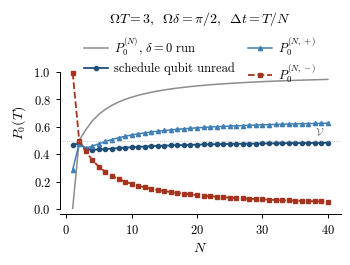

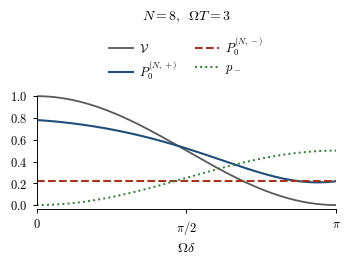

In [8]:
# The reference is a separate zero-offset run.
# The unread, plus, and minus curves use the offset run.
Omega, T = 1.0, 3.0

# panel (a) data: sweep N at fixed total relational interval and offset
OMEGA_DELTA_A = np.pi / 2          # offset for panel (a)
delta_a = OMEGA_DELTA_A / Omega

Ns        = np.arange(1, 41)
dts       = T / Ns
c_a       = np.cos(Omega * dts)
cN_a      = c_a ** Ns
cN1_a     = c_a ** (Ns - 1)
g2_a      = np.cos(Omega * delta_a / 2) ** 2

zeno_ref  = 0.5 * (1 + cN_a)                                    # zero-offset reference
P0A_a     = 0.5 * (1 + cN_a * np.cos(Omega * delta_a))
P0B_a     = 0.5 * (1 + cN1_a * np.cos(Omega * (dts + delta_a)))
marg      = 0.5 * (P0A_a + P0B_a)                               # schedule unread
anti      = 0.5 * (1 - cN_a)                                    # minus group
Pp_a      = 0.5 + (cN_a * g2_a + cN1_a * np.cos(Omega * (dts + delta_a))) \
                  / (2 * (1 + g2_a))

# the mixture must reproduce itself from the two branches
_chk = 0.5 * (1 + g2_a) * Pp_a + 0.5 * (1 - g2_a) * anti
assert np.abs(_chk - marg).max() < 1e-12, "branch weights inconsistent with marginal"
print(f"N=8:  delta=0 ref {zeno_ref[7]:.5f} | clock unread {marg[7]:.5f} | "
      f"P+ {Pp_a[7]:.5f} | P- {anti[7]:.5f}   (V = {g2_a:.3f})")

# panel (b) data: sweep the offset at fixed N
N, dt   = 8, T / 8
x       = np.linspace(1e-3, np.pi, 400)
delta   = x / Omega
cN, cN1 = np.cos(Omega * dt) ** N, np.cos(Omega * dt) ** (N - 1)
g2      = np.cos(Omega * delta / 2) ** 2
Pp      = 0.5 + (cN * g2 + cN1 * np.cos(Omega * (dt + delta))) / (2 * (1 + g2))
Pm      = 0.5 * (1 - cN) * np.ones_like(x)
pm      = 0.5 * (1 - g2)


def tidy(ax, ymax=1.09):
    ax.set_ylim(-0.04, ymax)
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.spines["left"].set_bounds(0.0, 1.0)   # no bare spine in the legend headroom
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


# panel (a)
figA, axA = plt.subplots(figsize=(COLUMN_WIDTH_IN, PANEL_HEIGHT_IN))
axA.plot(Ns, zeno_ref, "-",   lw=1.1,         color="0.55",
         label=r"$P_0^{(N)}$, $\delta=0$ run")
axA.plot(Ns, marg,     "o-",  ms=3.0, lw=1.3, color="#1f4e79",
         label=r"schedule qubit unread")
axA.plot(Ns, Pp_a,     "^-",  ms=3.0, lw=1.1, color="#3f7fb5",
         label=r"$P_0^{(N,+)}$")
axA.plot(Ns, anti,     "s--", ms=3.0, lw=1.3, color="#a5341f",
         label=r"$P_0^{(N,-)}$")
axA.axhline(g2_a, color="0.7", lw=0.6, ls=":")
axA.annotate(r"$\mathcal{V}$", xy=(39.4, g2_a), xytext=(39.4, g2_a + 0.035),
             color="0.45", fontsize=8, ha="right")
axA.set_xlabel(r"$N$")
axA.set_ylabel(r"$P_0(T)$")
axA.set_title(r"$\Omega T=3$,  $\Omega\delta=\pi/2$,  $\Delta t=T/N$")
tidy(axA, ymax=1.30)
axA.legend(frameon=False, loc="upper center", ncol=2,
           columnspacing=1.1, handletextpad=0.5, bbox_to_anchor=(0.5, 1.03))
figA.tight_layout(pad=0.35)
figA.savefig(FIG_A_PDF_PATH)
figA.savefig(FIG_A_PNG_PATH, dpi=300)

# panel (b)
figB, axB = plt.subplots(figsize=(COLUMN_WIDTH_IN, PANEL_HEIGHT_IN))
axB.plot(x, g2, "-",  lw=1.3, color="0.35",    label=r"$\mathcal{V}$")
axB.plot(x, Pp, "-",  lw=1.5, color="#1f4e79", label=r"$P_0^{(N,+)}$")
axB.plot(x, Pm, "--", lw=1.5, color="#a5341f", label=r"$P_0^{(N,-)}$")
axB.plot(x, pm, ":",  lw=1.4, color="#2e7d32", label=r"$p_-$")
axB.set_xlabel(r"$\Omega\delta$")
axB.set_xlim(0, np.pi)
axB.set_xticks([0, np.pi / 2, np.pi])
axB.set_xticklabels(["0", r"$\pi/2$", r"$\pi$"])
axB.set_title(r"$N=8$,  $\Omega T=3$")
tidy(axB, ymax=1.62)                     # headroom so the legend never sits on a curve
axB.legend(frameon=False, loc="upper center", ncol=2,
           columnspacing=1.4, handletextpad=0.5, bbox_to_anchor=(0.5, 1.02))
figB.tight_layout(pad=0.35)
figB.savefig(FIG_B_PDF_PATH)
figB.savefig(FIG_B_PNG_PATH, dpi=300)

for path in (FIG_A_PDF_PATH, FIG_B_PDF_PATH):
    print("wrote", path)
plt.show()

### Compare points with curves

Overlay exact circuit values on the formulas. The legend retains an equation number from an earlier draft. It refers to the complement relation.

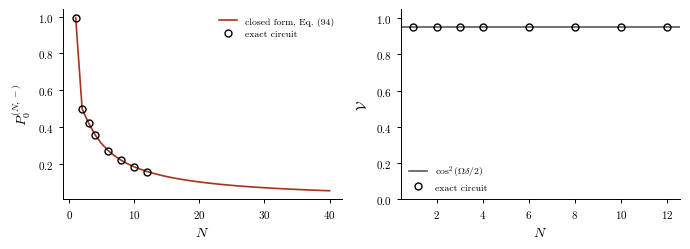

max |sim - closed form| for P0^(N,-) : 2.547e-13
max |sim - cos^2(Omega delta/2)| for V: 4.663e-15


In [9]:
# Overlay the analytic curves on the exact circuit values, as a final consistency check.
Omega, T, delta = 1.0, 3.0, 0.15 * 3.0
Ns_sim = np.array([1, 2, 3, 4, 6, 8, 10, 12])

sim_minus = np.array([numeric(N, Omega, T / N, delta)["Pminus"] for N in Ns_sim])
ana_minus = np.array([0.5 * (1 - np.cos(Omega * T / N) ** N) for N in Ns_sim])
sim_V     = np.array([numeric(N, Omega, T / N, delta)["V"] for N in Ns_sim])

fig2, ax2 = plt.subplots(1, 2, figsize=(7.0, 2.6))

ax2[0].plot(Ns, anti, "-", lw=1.2, color="#a5341f", label="closed form, Eq. (94)")
ax2[0].plot(Ns_sim, sim_minus, "o", ms=5, mfc="none", color="k", label="exact circuit")
ax2[0].set_xlabel(r"$N$"); ax2[0].set_ylabel(r"$P_0^{(N,-)}$")
ax2[0].legend(fontsize=7, frameon=False)

ax2[1].axhline(np.cos(Omega * delta / 2) ** 2, color="0.35", lw=1.2, label=r"$\cos^2(\Omega\delta/2)$")
ax2[1].plot(Ns_sim, sim_V, "o", ms=5, mfc="none", color="k", label="exact circuit")
ax2[1].set_xlabel(r"$N$"); ax2[1].set_ylabel(r"$\mathcal{V}$")
ax2[1].set_ylim(0, 1.05)
ax2[1].legend(fontsize=7, frameon=False)

for a in ax2:
    a.tick_params(labelsize=8)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
fig2.tight_layout(); plt.show()

print(f"max |sim - closed form| for P0^(N,-) : {np.abs(sim_minus - ana_minus).max():.3e}")
print(f"max |sim - cos^2(Omega delta/2)| for V: {np.abs(sim_V - np.cos(Omega*delta/2)**2).max():.3e}")

## What this calculation covers

The two schedule branches are simulated separately. The [verification notebook](ideal_circuit_verification.ipynb) also checks the circuit with an explicit schedule qubit and independent full matrices.

This notebook assumes ideal gates and no noise. The [memory-noise notebook](memory_parity_robustness.ipynb) studies a limited noise model. Neither notebook is a full hardware prediction. Numerical agreement checks the formulas, while their derivation belongs in the manuscript.